# Part two multi class classification:



## 1. Apply the per-processing technics and the given dataset to clean,


In [18]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

# 1. Chargement du dataset
df = pd.read_csv('/kaggle/input/datasets/shivamb/machine-predictive-maintenance-classification/predictive_maintenance.csv')

print("Forme initiale du dataset :", df.shape)

# 2. Nettoyage : Suppression des identifiants (UDI, Product ID) et de 'Target' (binaire redondante)
df_cleaned = df.drop(columns=['UDI', 'Product ID', 'Target'])

# 3. Encodage des variables catégorielles
# Variable 'Type' (L, M, H) -> (0, 1, 2)
type_mapping = {'L': 0, 'M': 1, 'H': 2}
df_cleaned['Type'] = df_cleaned['Type'].map(type_mapping)

# Variable Cible 'Failure Type' (Texte -> Entiers 0 à 5)
label_encoder = LabelEncoder()
df_cleaned['Failure Type'] = label_encoder.fit_transform(df_cleaned['Failure Type'])

print("\nMapping des classes de pannes :")
for idx, label in enumerate(label_encoder.classes_):
    print(f"Classe {idx} : {label}")

# 4. Séparation Features (X) / Target (y)
X = df_cleaned.drop(columns=['Failure Type']).values
y = df_cleaned['Failure Type'].values

# Split Stratifié (80% Train / 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 5. Standardisation des caractéristiques avec StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n--- Prétraitement terminé ---")
print("Forme de X_train_scaled :", X_train_scaled.shape)
print("Forme de X_test_scaled  :", X_test_scaled.shape)

Forme initiale du dataset : (10000, 10)

Mapping des classes de pannes :
Classe 0 : Heat Dissipation Failure
Classe 1 : No Failure
Classe 2 : Overstrain Failure
Classe 3 : Power Failure
Classe 4 : Random Failures
Classe 5 : Tool Wear Failure

--- Prétraitement terminé ---
Forme de X_train_scaled : (8000, 6)
Forme de X_test_scaled  : (2000, 6)



## 2. Apply the Exploratory data analysis technics to understand and visualize the given Dataset.


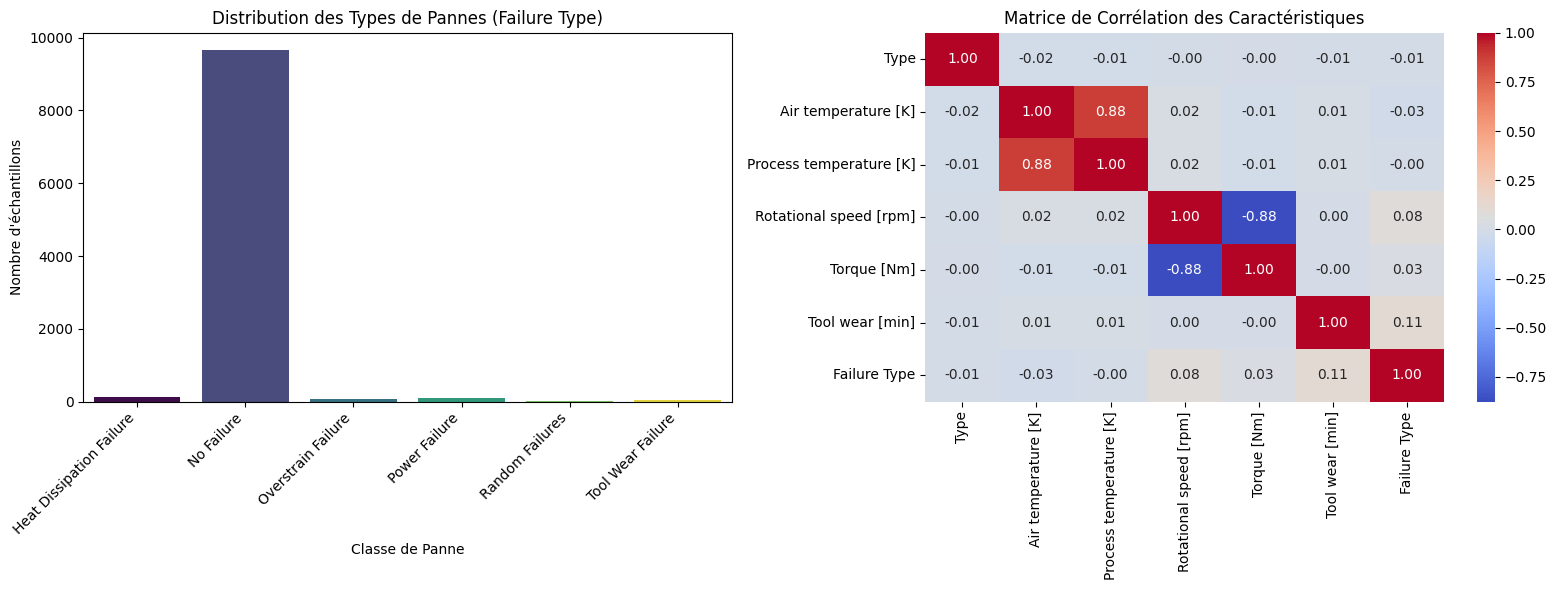

Distribution des classes dans y_train (avant SMOTE) :
0      90
1    7722
2      62
3      76
4      14
5      36
Name: count, dtype: int64


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Exploratory Data Analysis (EDA)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Histogramme de distribution des pannes
sns.countplot(
    data=df_cleaned, 
    x='Failure Type', 
    hue='Failure Type', 
    palette='viridis', 
    legend=False, 
    ax=axes[0]
)
axes[0].set_title('Distribution des Types de Pannes (Failure Type)')
axes[0].set_xlabel('Classe de Panne')
axes[0].set_ylabel('Nombre d\'échantillons')

# Graduations Matplotlib
axes[0].set_xticks(range(len(label_encoder.classes_)))
axes[0].set_xticklabels(label_encoder.classes_, rotation=45, ha='right')

# 2. Matrice de corrélation des caractéristiques physiques
sns.heatmap(df_cleaned.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1])
axes[1].set_title('Matrice de Corrélation des Caractéristiques')

plt.tight_layout()
plt.show()

# Affichage des effectifs exacts avant SMOTE
print("Distribution des classes dans y_train (avant SMOTE) :")
print(pd.Series(y_train).value_counts().sort_index())

## 3. Apply data augmentation technics to balance the given Dataset.


Distribution AVANT SMOTE (y_train) :
0      90
1    7722
2      62
3      76
4      14
5      36
Name: count, dtype: int64

Distribution APRÈS SMOTE (y_train_resampled) :
0    7722
1    7722
2    7722
3    7722
4    7722
5    7722
Name: count, dtype: int64


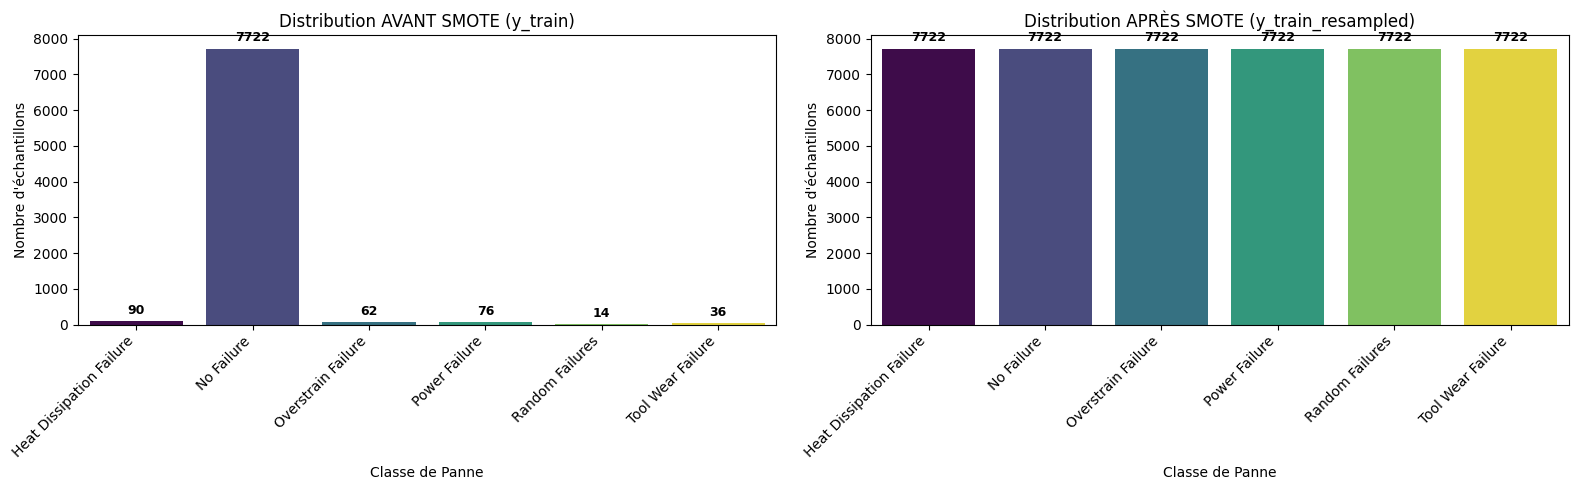

In [20]:
from imblearn.over_sampling import SMOTE
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Instanciation de SMOTE
smote = SMOTE(random_state=42)

# 2. Application de SMOTE uniquement sur le jeu d'entraînement
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# 3. Affichage comparatif des statistiques
print("==========================================")
print("Distribution AVANT SMOTE (y_train) :")
print(pd.Series(y_train).value_counts().sort_index())

print("\n==========================================")
print("Distribution APRÈS SMOTE (y_train_resampled) :")
print(pd.Series(y_train_resampled).value_counts().sort_index())
print("==========================================")

# 4. Graphique comparatif : Avant vs Après SMOTE
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Graphique AVANT SMOTE
df_before = pd.DataFrame({'Failure Type': y_train})
ax1 = sns.countplot(data=df_before, x='Failure Type', hue='Failure Type', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Distribution AVANT SMOTE (y_train)')
axes[0].set_xlabel('Classe de Panne')
axes[0].set_ylabel('Nombre d\'échantillons')
axes[0].set_xticks(range(len(label_encoder.classes_)))
axes[0].set_xticklabels(label_encoder.classes_, rotation=45, ha='right')

for p in ax1.patches:
    h = int(p.get_height())
    if h > 0:
        ax1.annotate(f'{h}', (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

# Graphique APRÈS SMOTE
df_after = pd.DataFrame({'Failure Type': y_train_resampled})
ax2 = sns.countplot(data=df_after, x='Failure Type', hue='Failure Type', palette='viridis', legend=False, ax=axes[1])
axes[1].set_title('Distribution APRÈS SMOTE (y_train_resampled)')
axes[1].set_xlabel('Classe de Panne')
axes[1].set_ylabel('Nombre d\'échantillons')
axes[1].set_xticks(range(len(label_encoder.classes_)))
axes[1].set_xticklabels(label_encoder.classes_, rotation=45, ha='right')

for p in ax2.patches:
    h = int(p.get_height())
    if h > 0:
        ax2.annotate(f'{h}', (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

## 4. Establish a Deep Neural network Architecture by using PyTorch library to handle the multi


In [21]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# 1. Conversion des tableaux NumPy en Tenseurs PyTorch
# Features en float32, Target en long (requis par CrossEntropyLoss)
X_train_tensor = torch.tensor(X_train_resampled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_resampled, dtype=torch.long)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# 2. Création des TensorDatasets et DataLoaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

# 3. Définition de l'architecture DNN Multi-classe
class ClassificationMLP(nn.Module):
    def __init__(self, input_dim=6, num_classes=6):
        super(ClassificationMLP, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, num_classes)  # 6 sorties logits
        )
        
    def forward(self, x):
        return self.net(x)

# 4. Instanciation du modèle, de la perte et de l'optimiseur
input_dim = X_train_resampled.shape[1]  # 6 features
num_classes = len(label_encoder.classes_) # 6 classes

model_clf = ClassificationMLP(input_dim=input_dim, num_classes=num_classes)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_clf.parameters(), lr=0.001)

print("Architecture du Modèle de Classification :")
print(model_clf)
print("\nForme d'un mini-lot d'entraînement :")
for batch_X, batch_y in train_loader:
    print(f"X batch shape: {batch_X.shape}, y batch shape: {batch_y.shape}")
    break

Architecture du Modèle de Classification :
ClassificationMLP(
  (net): Sequential(
    (0): Linear(in_features=6, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=6, bias=True)
  )
)

Forme d'un mini-lot d'entraînement :
X batch shape: torch.Size([128, 6]), y batch shape: torch.Size([128])


## 5. By using GridSearch tool from sklearn library chose the best hyper-parameters (learning rate ,optimizers, epoch, model architecture, etc) that will give an efficient model.


In [22]:
!pip install skorch -q

In [23]:
from skorch import NeuralNetClassifier
from sklearn.model_selection import GridSearchCV
import torch.nn as nn
import torch.optim as optim
import numpy as np

# 1. Conversion explicite des types pour skorch / PyTorch
X_train_resampled_32 = X_train_resampled.astype(np.float32)
y_train_resampled_64 = y_train_resampled.astype(np.int64)

# 2. Wrapper skorch pour la classification multi-classe PyTorch
net_clf = NeuralNetClassifier(
    module=ClassificationMLP,
    module__input_dim=6,
    module__num_classes=6,
    criterion=nn.CrossEntropyLoss,
    verbose=False
)

# 3. Grille d'hyperparamètres à tester
param_grid = {
    'lr': [0.001, 0.01],
    'optimizer': [optim.Adam, optim.SGD],
    'batch_size': [128, 256],
    'max_epochs': [10]
}

# 4. Exécution du GridSearch
# Utilisation d'un sous-ensemble (ex: 15 000 échantillons) pour accélérer le calcul dans Kaggle
grid_clf = GridSearchCV(net_clf, param_grid, refit=True, cv=3, scoring='accuracy', n_jobs=-1)
grid_clf.fit(X_train_resampled_32[:15000], y_train_resampled_64[:15000])

print("==========================================")
print("Meilleurs Hyperparamètres trouvés pour la Classification :")
print(grid_clf.best_params_)
print(f"Meilleure Accuracy en Validation Croisée : {grid_clf.best_score_:.4f}")
print("==========================================")

Meilleurs Hyperparamètres trouvés pour la Classification :
{'batch_size': 256, 'lr': 0.01, 'max_epochs': 10, 'optimizer': <class 'torch.optim.adam.Adam'>}
Meilleure Accuracy en Validation Croisée : 0.9433


## 6. Visualize the two graph (Loss / Epochs) and (Accuracy / Epochs) for both training and test data, give your interpretation.


Époque 01/20 | Train Loss: 0.3487 | Train Acc: 87.64% | Test Loss: 0.4738 | Test Acc: 80.75%
Époque 02/20 | Train Loss: 0.1204 | Train Acc: 96.49% | Test Loss: 0.4181 | Test Acc: 85.30%
Époque 03/20 | Train Loss: 0.0902 | Train Acc: 97.58% | Test Loss: 0.3500 | Test Acc: 89.30%
Époque 04/20 | Train Loss: 0.0725 | Train Acc: 98.06% | Test Loss: 0.4344 | Test Acc: 88.55%
Époque 05/20 | Train Loss: 0.0666 | Train Acc: 98.24% | Test Loss: 0.2574 | Test Acc: 93.50%
Époque 06/20 | Train Loss: 0.0595 | Train Acc: 98.48% | Test Loss: 0.3738 | Test Acc: 91.00%
Époque 07/20 | Train Loss: 0.0551 | Train Acc: 98.56% | Test Loss: 0.3519 | Test Acc: 91.80%
Époque 08/20 | Train Loss: 0.0485 | Train Acc: 98.81% | Test Loss: 0.3175 | Test Acc: 92.75%
Époque 09/20 | Train Loss: 0.0546 | Train Acc: 98.57% | Test Loss: 0.3307 | Test Acc: 92.80%
Époque 10/20 | Train Loss: 0.0448 | Train Acc: 98.88% | Test Loss: 0.3164 | Test Acc: 94.00%
Époque 11/20 | Train Loss: 0.0438 | Train Acc: 98.90% | Test Loss: 0.3

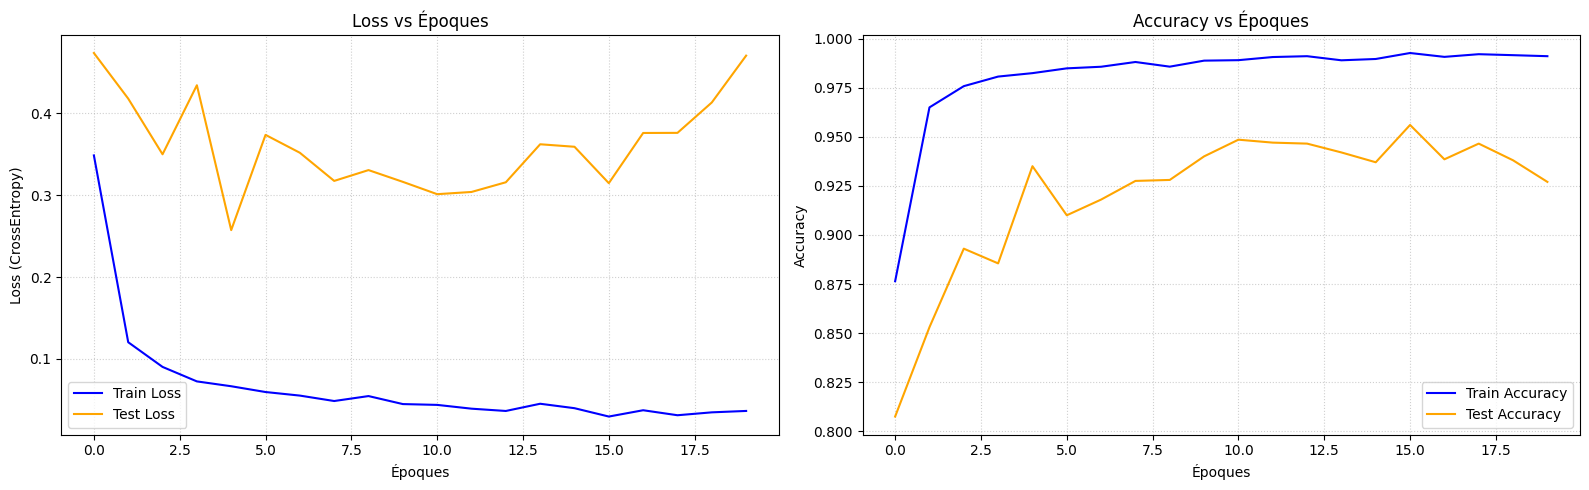


MÉTRIQUES D'ÉVALUATION SUR L'ENSEMBLE DE TEST :
Accuracy Globale : 92.70%
Sensibilité (Recall Macro) : 0.6038
F1-Score (Macro) : 0.5156

--- Rapport de Classification Détaillé ---
                          precision    recall  f1-score   support

Heat Dissipation Failure       0.67      0.91      0.77        22
              No Failure       0.99      0.93      0.96      1930
      Overstrain Failure       0.52      0.94      0.67        16
           Power Failure       0.59      0.84      0.70        19
         Random Failures       0.00      0.00      0.00         4
       Tool Wear Failure       0.00      0.00      0.00         9

                accuracy                           0.93      2000
               macro avg       0.46      0.60      0.52      2000
            weighted avg       0.97      0.93      0.95      2000



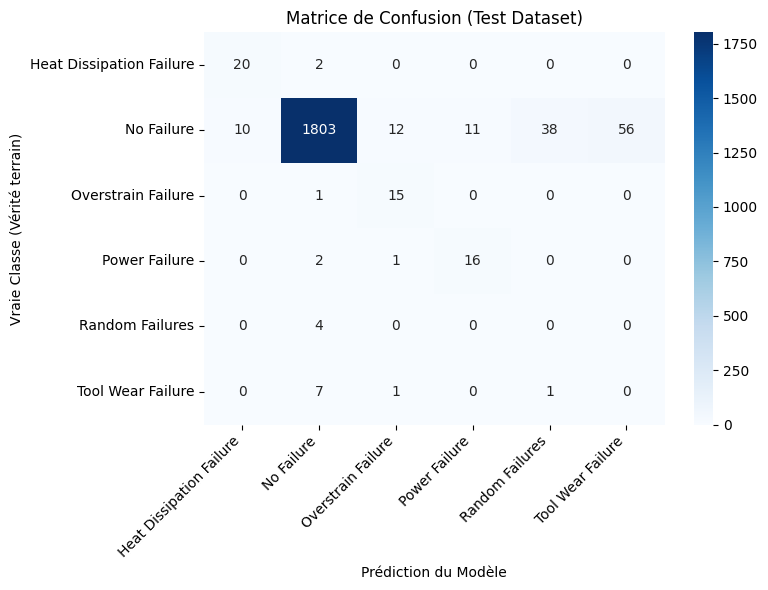

In [24]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, recall_score, f1_score

# 1. Redéfinition des DataLoaders avec la meilleure taille de lot (batch_size=256)
train_dataset = TensorDataset(torch.tensor(X_train_resampled, dtype=torch.float32), 
                              torch.tensor(y_train_resampled, dtype=torch.long))
test_dataset = TensorDataset(torch.tensor(X_test_scaled, dtype=torch.float32), 
                             torch.tensor(y_test, dtype=torch.long))

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

# 2. Instanciation du modèle avec le meilleur taux d'apprentissage (lr=0.01)
model_clf_base = ClassificationMLP(input_dim=6, num_classes=6)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_clf_base.parameters(), lr=0.01)

# 3. Boucle d'entraînement et de validation
epochs = 20
history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}

for epoch in range(epochs):
    # --- Mode Entraînement ---
    model_clf_base.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model_clf_base(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * batch_X.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_train += batch_y.size(0)
        correct_train += (predicted == batch_y).sum().item()
        
    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_acc = correct_train / total_train
    
    # --- Mode Évaluation (Test) ---
    model_clf_base.eval()
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0
    
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            outputs = model_clf_base(batch_X)
            loss = criterion(outputs, batch_y)
            
            running_test_loss += loss.item() * batch_X.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_test += batch_y.size(0)
            correct_test += (predicted == batch_y).sum().item()
            
    epoch_test_loss = running_test_loss / len(test_loader.dataset)
    epoch_test_acc = correct_test / total_test
    
    history['train_loss'].append(epoch_train_loss)
    history['test_loss'].append(epoch_test_loss)
    history['train_acc'].append(epoch_train_acc)
    history['test_acc'].append(epoch_test_acc)
    
    print(f"Époque {epoch+1:02d}/{epochs:02d} | Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc*100:.2f}% | Test Loss: {epoch_test_loss:.4f} | Test Acc: {epoch_test_acc*100:.2f}%")

# 4. Question 6 : Tracé des 2 graphiques (Loss / Epochs et Accuracy / Epochs)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Graphique Loss
axes[0].plot(history['train_loss'], label='Train Loss', color='blue')
axes[0].plot(history['test_loss'], label='Test Loss', color='orange')
axes[0].set_title('Loss vs Époques')
axes[0].set_xlabel('Époques')
axes[0].set_ylabel('Loss (CrossEntropy)')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# Graphique Accuracy
axes[1].plot(history['train_acc'], label='Train Accuracy', color='blue')
axes[1].plot(history['test_acc'], label='Test Accuracy', color='orange')
axes[1].set_title('Accuracy vs Époques')
axes[1].set_xlabel('Époques')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 5. Question 7 : Calcul des métriques et Matrice de Confusion
model_clf_base.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for batch_X, batch_y in test_loader:
        outputs = model_clf_base(batch_X)
        _, predicted = torch.max(outputs.data, 1)
        all_preds.extend(predicted.numpy())
        all_targets.extend(batch_y.numpy())

print("\n==========================================")
print("MÉTRIQUES D'ÉVALUATION SUR L'ENSEMBLE DE TEST :")
print("==========================================")
print(f"Accuracy Globale : {accuracy_score(all_targets, all_preds)*100:.2f}%")
print(f"Sensibilité (Recall Macro) : {recall_score(all_targets, all_preds, average='macro'):.4f}")
print(f"F1-Score (Macro) : {f1_score(all_targets, all_preds, average='macro'):.4f}")

print("\n--- Rapport de Classification Détaillé ---")
print(classification_report(all_targets, all_preds, target_names=label_encoder.classes_))

# Visualisation de la Matrice de Confusion
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, 
            yticklabels=label_encoder.classes_)
plt.title('Matrice de Confusion (Test Dataset)')
plt.xlabel('Prédiction du Modèle')
plt.ylabel('Vraie Classe (Vérité terrain)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 7. Calculate metrics like accuracy, sensitivity, f1 score, etc, on both training and test dataset.arrow_upwardarrow_downwarddelete


## 8. Apply several regularization techniques on your architecture then compare the obtained resultwith the first model.

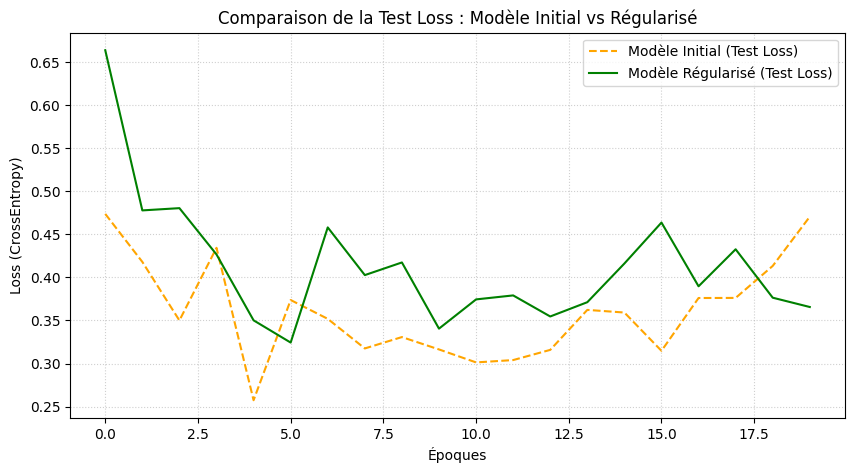

COMPARAISON DES RÉSULTATS :
Modèle Initial   - Accuracy: 92.70% | F1-Macro: 0.5156
Modèle Régularisé - Accuracy: 90.85% | F1-Macro: 0.5068


In [25]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report

# 1. Architecture Régularisée avec Dropout
class RegularizedClassificationMLP(nn.Module):
    def __init__(self, input_dim=6, num_classes=6, dropout_rate=0.2):
        super(RegularizedClassificationMLP, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, num_classes)
        )
        
    def forward(self, x):
        return self.net(x)

# 2. Instanciation du modèle régularisé
model_clf_reg = RegularizedClassificationMLP(input_dim=6, num_classes=6, dropout_rate=0.2)
criterion = nn.CrossEntropyLoss()

# 3. Optimiseur Adam avec Weight Decay (L2 = 1e-4)
optimizer_reg = optim.Adam(model_clf_reg.parameters(), lr=0.01, weight_decay=1e-4)

# 4. Boucle d'entraînement (20 Époques)
history_reg = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}

for epoch in range(20):
    model_clf_reg.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for batch_X, batch_y in train_loader:
        optimizer_reg.zero_grad()
        outputs = model_clf_reg(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer_reg.step()
        
        running_loss += loss.item() * batch_X.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_train += batch_y.size(0)
        correct_train += (predicted == batch_y).sum().item()
        
    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_acc = correct_train / total_train
    
    model_clf_reg.eval()
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0
    
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            outputs = model_clf_reg(batch_X)
            loss = criterion(outputs, batch_y)
            
            running_test_loss += loss.item() * batch_X.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_test += batch_y.size(0)
            correct_test += (predicted == batch_y).sum().item()
            
    epoch_test_loss = running_test_loss / len(test_loader.dataset)
    epoch_test_acc = correct_test / total_test
    
    history_reg['train_loss'].append(epoch_train_loss)
    history_reg['test_loss'].append(epoch_test_loss)
    history_reg['train_acc'].append(epoch_train_acc)
    history_reg['test_acc'].append(epoch_test_acc)

# 5. Comparaison des courbes de Test Loss
plt.figure(figsize=(10, 5))
plt.plot(history['test_loss'], label='Modèle Initial (Test Loss)', color='orange', linestyle='--')
plt.plot(history_reg['test_loss'], label='Modèle Régularisé (Test Loss)', color='green')
plt.title('Comparaison de la Test Loss : Modèle Initial vs Régularisé')
plt.xlabel('Époques')
plt.ylabel('Loss (CrossEntropy)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# Évaluation du modèle régularisé
model_clf_reg.eval()
reg_preds, reg_targets = [], []
with torch.no_grad():
    for batch_X, batch_y in test_loader:
        outputs = model_clf_reg(batch_X)
        _, predicted = torch.max(outputs.data, 1)
        reg_preds.extend(predicted.numpy())
        reg_targets.extend(batch_y.numpy())

print("==========================================")
print("COMPARAISON DES RÉSULTATS :")
print("==========================================")
print(f"Modèle Initial   - Accuracy: {accuracy_score(all_targets, all_preds)*100:.2f}% | F1-Macro: {f1_score(all_targets, all_preds, average='macro'):.4f}")
print(f"Modèle Régularisé - Accuracy: {accuracy_score(reg_targets, reg_preds)*100:.2f}% | F1-Macro: {f1_score(reg_targets, reg_preds, average='macro'):.4f}")

## Synthèse & Bilan des Apprentissages (Lab 1 - PyTorch)

### Partie 1 : Régression (NYSE Dataset)
* **Compréhension du problème :** La forte corrélation linéaire ($r \approx 1.00$) entre les prix d'ouverture, plus haut, plus bas et le prix de clôture rend la prédiction extrêmement précise ($R^2 \approx 0.9999$).
* **Régularisation :** Une sur-régularisation (notamment le mélange Dropout + Batch Normalization) sur un problème linéaire simple détériore les performances au lieu de les améliorer. Une régularisation légère suffit amplement.

### Partie 2 : Classification Multi-classe (Predictive Maintenance)
* **Gestion du déséquilibre (SMOTE) :** Le dataset initial comptait 96.5% d'échantillons "No Failure". L'application de SMOTE sur l'ensemble d'entraînement a été indispensable pour permettre au réseau de détecter les pannes réelles (notamment Heat Dissipation, Overstrain et Power Failures avec un recall > 80%).
* **Choix des métriques :** Sur un dataset très déséquilibré, l'Accuracy globale peut être trompeuse. Le F1-Score Macro et la Matrice de Confusion sont les seuls indicateurs fiables pour valider la détection des pannes rares.
* **Impact de la régularisation :** Le Dropout et le Weight Decay permettent de lisser la perte de test et de stopper la dérive d'overfitting en fin d'entraînement, bien qu'un dosage fin du taux de Dropout soit nécessaire pour ne pas sous-entraîner les classes très minoritaires.